# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**:
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## 1. Setup and Data Loading

In [12]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['china', 'europe', 'japan', 'korea', 'us']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [ ]:
# Data containers
data = {
    'total_ER': {},
    'beta': {},
    'factor_result': {},
    'factor_ts': {},
    'sector_ts': {},
    'industry_ER': {},
    'subindustry_ER': {},
    'size_ER': {},
    'top_bot': {},
    'wmean_ER': {}
}

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country
    
    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv')
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv')
    data['factor_result'][country] = pd.read_csv(country_path / 'factor_result.csv')
    factor_ts = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)[-52:]
    factor_ts = (factor_ts / factor_ts.iloc[0]) * 100
    data['factor_ts'][country] = factor_ts
    sector_ts = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)[-52:]
    sector_ts = (sector_ts / sector_ts.iloc[0]) * 100
    data['sector_ts'][country] = sector_ts
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv')
    data['subindustry_ER'][country] = pd.read_csv(country_path / 'subindustry_ER.csv')
    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv')
    data['wmean_ER'][country] = pd.read_csv(country_path / 'wmean_ER.csv')

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

# ============================================================================
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# ============================================================================
# Since factor models have different scales across countries, we need to 
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def percentile_rank(series):
    """Convert to percentile ranks (0-100)"""
    return series.rank(pct=True) * 100

def minmax_normalize(series, new_min=0, new_max=100):
    """Normalize to [new_min, new_max] range"""
    return (series - series.min()) / (series.max() - series.min()) * (new_max - new_min) + new_min

def normalize_country_data(df, value_col, method='zscore'):
    """Normalize a value column within each country"""
    if method == 'zscore':
        return zscore_normalize(df[value_col])
    elif method == 'percentile':
        return percentile_rank(df[value_col])
    elif method == 'minmax':
        return minmax_normalize(df[value_col])
    return df[value_col]

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
normalized_data = {
    'total_ER': {},
    'industry_ER': {},
    'factor_result': {}
}

for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
        total_er['ER_percentile'] = percentile_rank(total_er['ER'])
    normalized_data['total_ER'][country] = total_er
    
    # Normalize sector ERs
    ind_er = data['industry_ER'][country].copy()
    if 'ER' in ind_er.columns:
        ind_er['ER_zscore'] = zscore_normalize(ind_er['ER'])
        ind_er['ER_percentile'] = percentile_rank(ind_er['ER'])
    normalized_data['industry_ER'][country] = ind_er
    
    # Normalize factor returns (relative strength within country)
    fr = data['factor_result'][country].copy()
    if 'factor_return' in fr.columns:
        fr['return_zscore'] = zscore_normalize(fr['factor_return'])
        fr['return_percentile'] = percentile_rank(fr['factor_return'])
    normalized_data['factor_result'][country] = fr

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Percentile: Ranked 0-100 within country - intuitive interpretation")
print("  • Note: Use normalized values for cross-country comparisons")

---
## 2. Factor Performance Analysis

### 2.1 Factor Returns Summary (All Countries)

In [ ]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("\n⚠️  NOTE: Raw values have different scales across countries.")
print("    Use Z-Score or Percentile for valid cross-country comparisons.\n")

# Raw factor returns
factor_returns_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_result'][country].set_index('factor')['factor_return']
    factor_returns_df[country.upper()] = fr
factor_returns_df = factor_returns_df.T

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = normalized_data['factor_result'][country].set_index('factor')['return_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

# Percentile rank (within each country)
factor_percentile_df = pd.DataFrame()
for country in COUNTRIES:
    fr = normalized_data['factor_result'][country].set_index('factor')['return_percentile']
    factor_percentile_df[country.upper()] = fr
factor_percentile_df = factor_percentile_df.T

print("\n[1] RAW FACTOR RETURNS (%) - Different scales, NOT comparable across countries")
print("-"*70)
display(factor_returns_df.style.format('{:.4f}').background_gradient(cmap='RdYlGn', axis=1))

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

print("\n[3] PERCENTILE RANK - Comparable across countries (100 = best factor in country)")
print("-"*70)
display(factor_percentile_df.style.format('{:.0f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

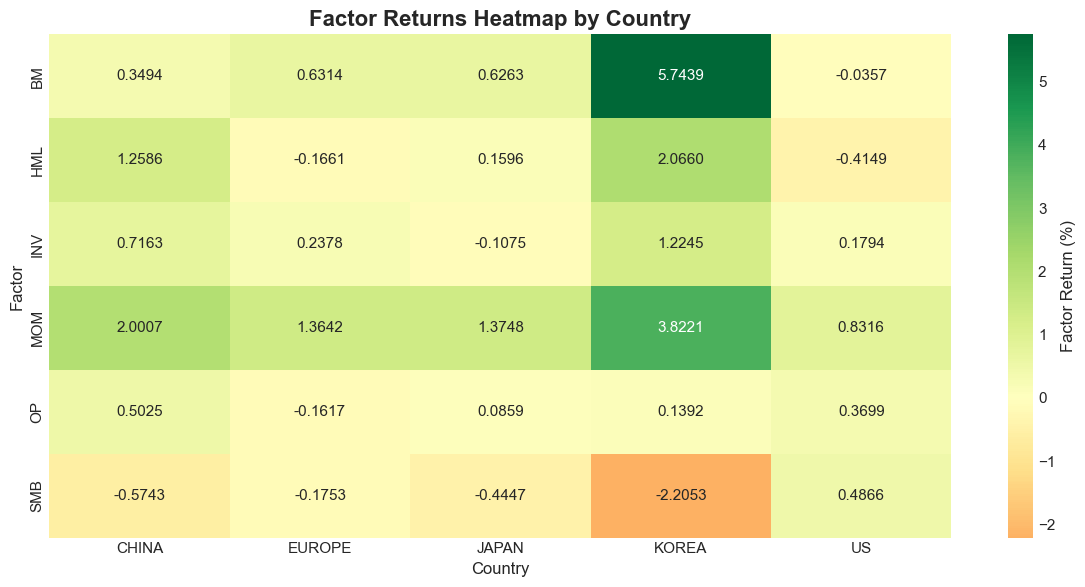

In [15]:
# Factor returns heatmap
fig, ax = plt.subplots(figsize=(12, 6))

# Transpose for better visualization
plot_data = factor_returns_df.drop('Average', axis=1).T

sns.heatmap(plot_data, annot=True, fmt='.4f', cmap='RdYlGn', center=0,
            ax=ax, cbar_kws={'label': 'Factor Return (%)'})
ax.set_title('Factor Returns Heatmap by Country', fontsize=16, fontweight='bold')
ax.set_xlabel('Country')
ax.set_ylabel('Factor')
plt.tight_layout()
plt.show()

### 2.2 Factor Time Series Performance

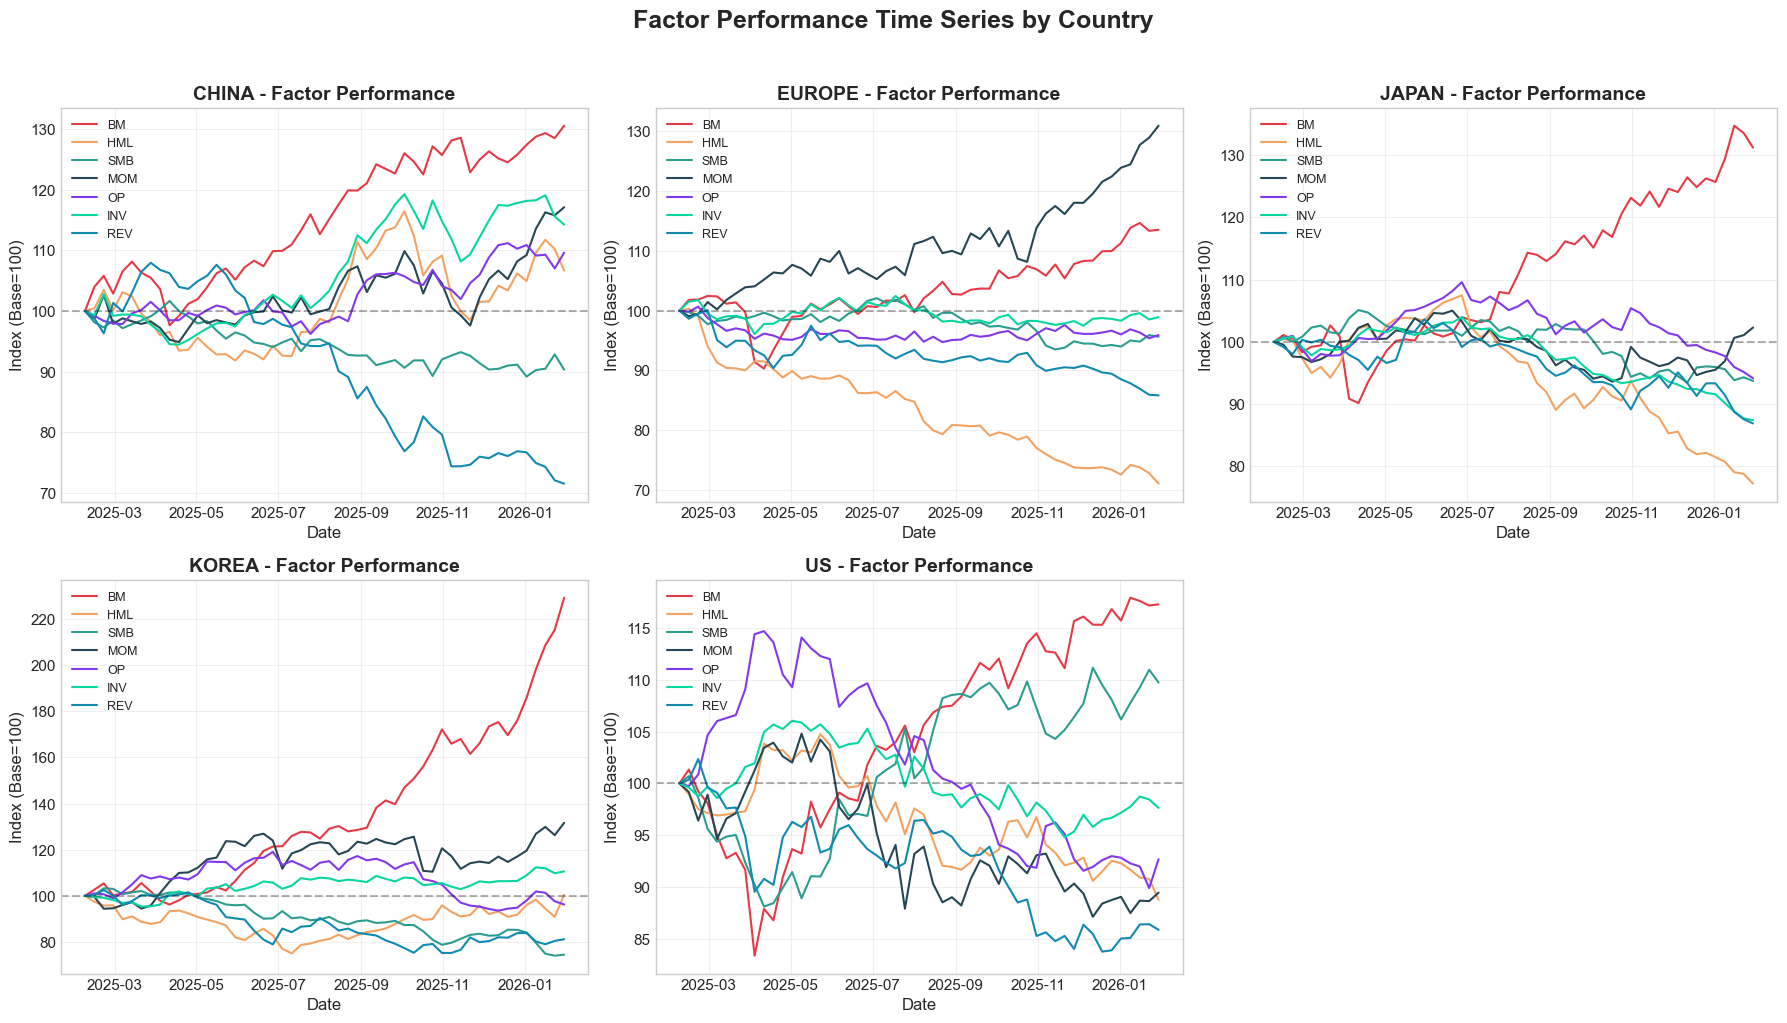

In [16]:
# Plot factor time series for each country
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_ts'][country]
    
    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col, 
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)
    
    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [17]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()
    
    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_ts'][country])
    display(stats.style.format('{:.3f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,30.508,28.242,14.396,1.962,-9.699,-0.901,1.083
HML,6.656,8.307,18.783,0.442,-15.404,-0.179,-0.273
SMB,-9.658,-9.918,9.337,-1.062,-12.240,0.152,-0.214
MOM,17.089,17.438,16.454,1.060,-11.149,-0.175,-0.497
OP,9.610,9.923,10.702,0.927,-5.448,0.411,0.176
INV,14.242,14.516,13.722,1.058,-9.311,-0.157,-0.564
REV,-28.428,-32.579,16.942,-1.923,-33.696,0.250,0.679



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,13.536,13.887,13.608,1.021,-11.876,-1.839,7.679
HML,-28.972,-34.285,9.827,-3.489,-29.190,-0.600,1.552
SMB,-4.361,-4.353,6.239,-0.698,-8.402,-0.434,0.147
MOM,30.957,28.378,12.850,2.208,-4.971,-0.050,1.181
OP,-4.082,-4.074,5.946,-0.685,-5.900,-0.205,-0.644
INV,-1.090,-0.866,7.157,-0.121,-5.574,-0.288,-0.009
REV,-14.186,-15.127,9.532,-1.587,-14.250,-0.441,2.876



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,31.214,29.163,16.664,1.750,-12.169,-1.680,7.171
HML,-22.788,-25.346,13.943,-1.818,-28.165,0.165,-0.439
SMB,-6.290,-6.280,8.314,-0.755,-11.096,-0.024,0.752
MOM,2.305,2.929,11.156,0.263,-10.867,0.869,1.831
OP,-5.852,-5.732,9.175,-0.625,-14.096,0.084,-0.078
INV,-12.581,-13.511,6.063,-2.229,-15.917,-0.001,-0.745
REV,-13.112,-13.655,11.595,-1.178,-16.168,0.816,0.440



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,129.309,87.570,21.563,4.061,-8.825,-0.413,-0.508
HML,0.333,3.154,24.058,0.131,-25.009,0.426,0.906
SMB,-25.564,-28.997,14.317,-2.025,-28.312,-0.542,0.503
MOM,31.613,31.653,26.741,1.184,-12.999,-0.892,2.554
OP,-3.817,-2.428,17.678,-0.137,-21.420,-0.180,-0.077
INV,10.558,10.896,11.577,0.941,-5.281,0.575,0.677
REV,-18.855,-19.125,20.944,-0.913,-26.660,0.685,1.177



US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,17.281,17.767,17.336,1.025,-17.731,-0.778,3.826
HML,-11.239,-11.475,11.666,-0.984,-15.266,0.386,0.370
SMB,9.727,10.561,14.936,0.707,-12.496,0.271,0.401
MOM,-10.544,-9.799,17.707,-0.553,-16.864,-0.325,0.240
OP,-7.315,-6.806,13.851,-0.491,-21.621,0.809,0.833
INV,-2.371,-2.048,9.016,-0.227,-10.598,0.254,0.142
REV,-14.130,-14.606,13.562,-1.077,-18.159,0.119,1.779


### 2.3 Factor Correlation Analysis

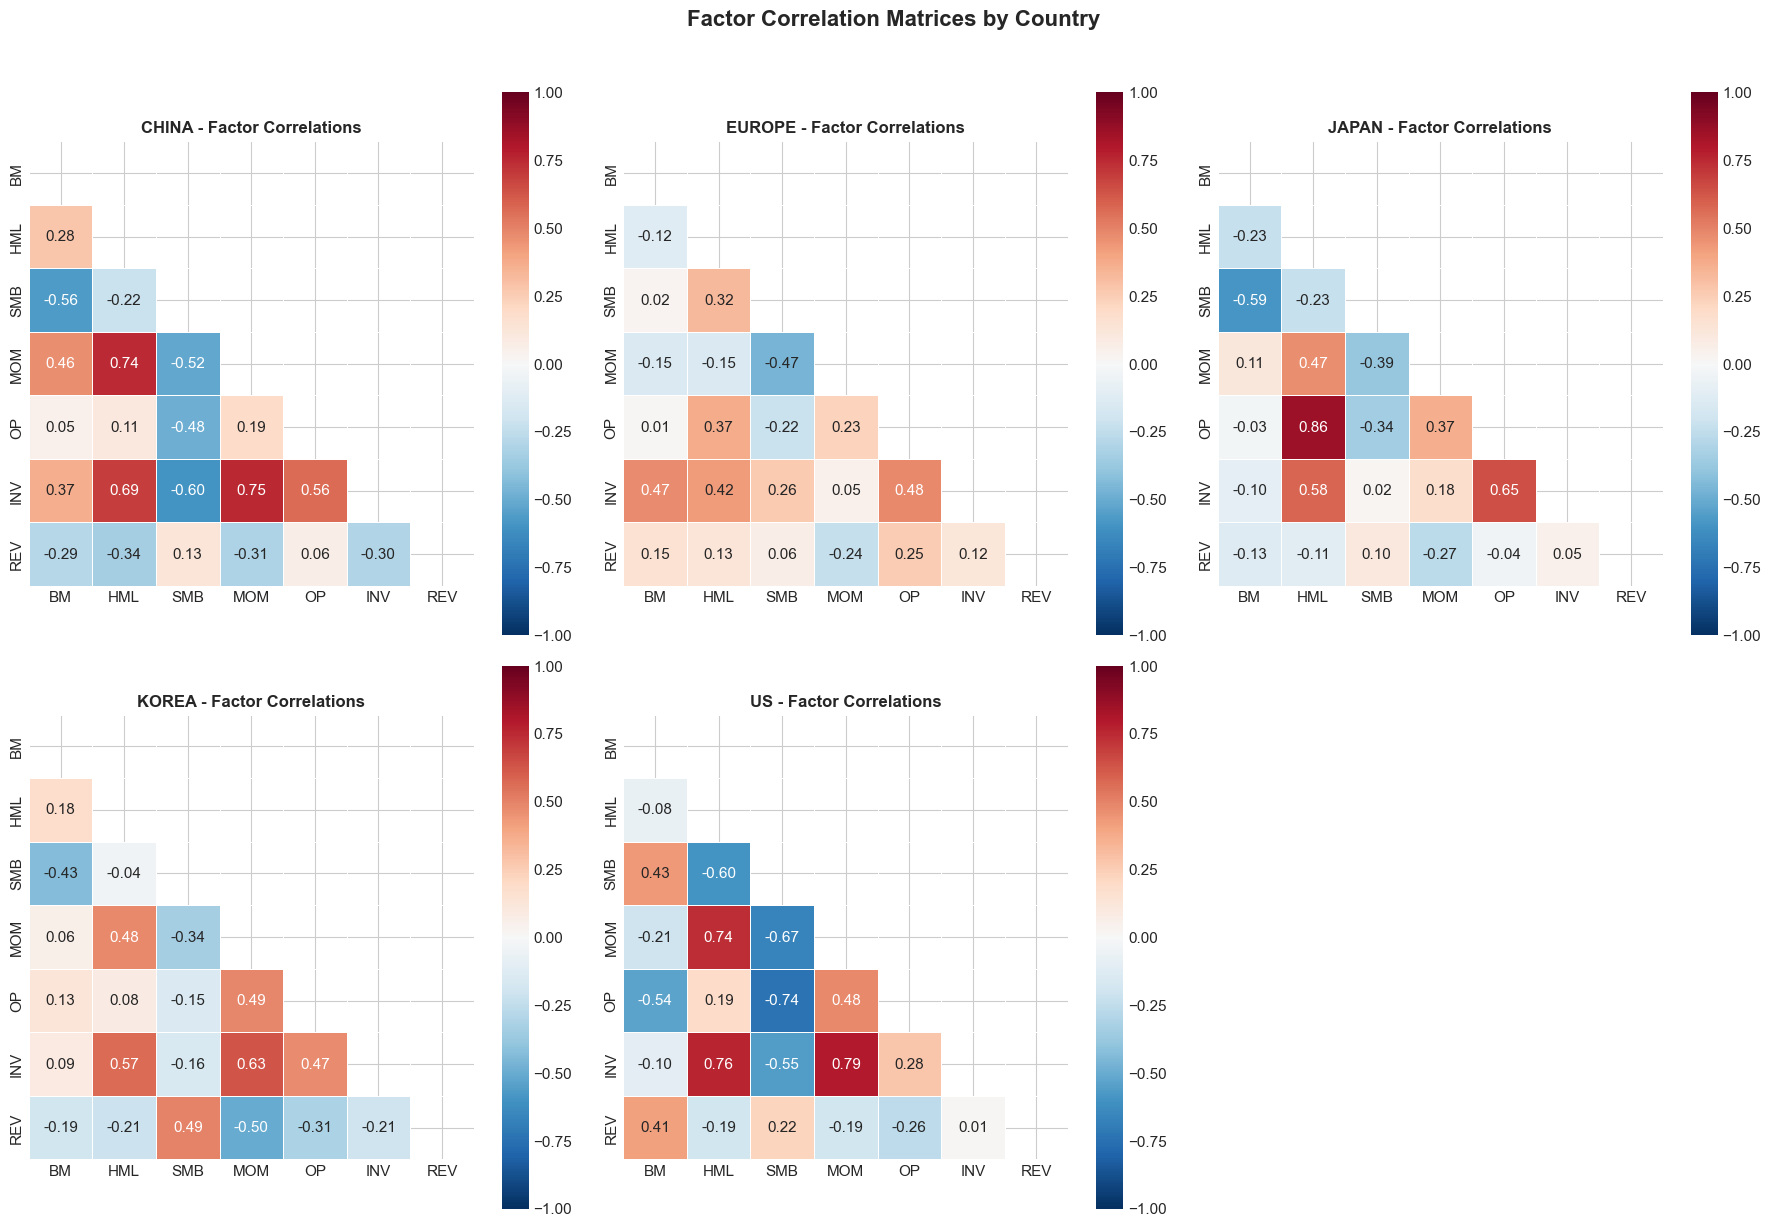

In [18]:
# Factor correlation matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_ts'][country].pct_change().dropna()
    corr = factor_returns.corr()
    
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', 
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 2.4 Top Performers by Factor Exposure

In [19]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)
    
    top_bot = data['top_bot'][country]
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'ER', 'Vol', 'Sharpe', 'mktval', 'industry']]
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,instrument,ER,Vol,Sharpe,mktval,industry
3,CNE1000020V4,3.461084,20.652432,0.167587,142221.974561,45.0
13,HK0000218211,3.417280,23.876114,0.143125,119215.486742,45.0
9,CNE100002CC3,3.097254,20.329865,0.152350,54931.000798,NaN
15,CNE100004413,3.055431,21.581380,0.141577,66829.208034,45.0
0,CA16890P1036,3.013292,15.885333,0.189690,43402.066007,NaN
10,CNE100001CY9,2.847429,18.983298,0.149997,516666.996787,45.0
16,CNE100006JG0,2.586146,18.749332,0.137933,34397.049338,25.0
2,CNE1000030S9,2.470192,14.702780,0.168008,188897.777788,45.0
7,CNE000000D24,2.353887,15.013798,0.156782,67689.861386,NaN
5,CNE000000BL1,2.331508,14.455537,0.161288,36826.921964,15.0



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,instrument,ER,Vol,Sharpe,mktval,industry
1,PLKGHM000017,4.725927,10.350820,0.456575,10767.939400,15
0,DE000BAY0017,4.560851,9.698532,0.470262,43693.300000,35
10,GB00B2QPKJ12,4.528855,14.334155,0.315949,7867.829690,15
18,CH0311864901,3.622839,12.644136,0.286523,14736.144811,20
4,SE0020050417,3.357863,9.549261,0.351636,16605.991569,15
14,DE0006766504,3.002329,10.034753,0.299193,4925.142609,15
15,IT0005495657,2.910473,9.895455,0.294122,4053.006343,10
2,IL0011284465,2.820004,7.126342,0.395716,3291.858072,40
6,FR0000131104,2.734914,7.892301,0.346529,89164.189511,40
11,LU0075646355,2.515174,8.165021,0.308043,4896.247141,10



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,instrument,ER,Vol,Sharpe,mktval,industry
15,JP3891600003,2.851558,16.657990,0.171183,6.632991e+05,20.0
12,JP3888400003,2.712562,15.321793,0.177039,1.092420e+06,15.0
4,JP3842400008,1.781616,9.113531,0.195491,5.777810e+05,40.0
3,JP3309000002,1.692161,8.506699,0.198921,4.459976e+05,20.0
0,JP3230600003,1.566066,6.210628,0.252159,5.664740e+05,20.0
1,JP3443600006,1.483314,6.799379,0.218154,2.514762e+06,20.0
2,JP3210200006,1.478785,7.299037,0.202600,2.965599e+06,20.0
13,JP3877600001,1.456830,8.308330,0.175346,7.529635e+06,20.0
7,JP3358800005,1.455834,7.909242,0.184067,1.431958e+06,20.0
14,JP3263000006,1.392632,7.956790,0.175024,7.630727e+05,20.0



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,instrument,ER,Vol,Sharpe,mktval,industry
2,KR7402340004,11.251385,18.299291,0.614854,5.104924e+07,20.0
17,KR7240810002,9.719022,21.204674,0.458343,3.314522e+06,45.0
0,KR7000660001,9.397771,14.089106,0.667024,5.190043e+08,45.0
9,KR7042700005,9.332549,18.574696,0.502433,8.880956e+06,45.0
3,KR7006800007,8.822030,15.093999,0.584473,1.221583e+07,40.0
5,KR7039490008,8.188934,14.899839,0.549599,6.631681e+06,40.0
4,KR7298040007,8.167755,14.748884,0.553788,1.239852e+07,20.0
15,KR7039030002,7.808903,16.956663,0.460521,3.162179e+06,45.0
13,KR7000990002,7.412376,15.841304,0.467914,3.515436e+06,45.0
12,KR7010120004,7.103585,15.079638,0.471071,8.668144e+06,20.0



----------------------------------------------------------------------
US
----------------------------------------------------------------------


,instrument,ER,Vol,Sharpe,mktval,industry
3,US6078281002,11.938581,17.802563,0.670610,9573.507173,20.0
5,US87305R1095,11.213869,17.461282,0.642213,9921.399163,45.0
17,US60770K1079,9.401235,18.811753,0.499753,15965.814184,35.0
4,US55405Y1001,8.440979,12.799859,0.659459,13948.858613,45.0
1,US2193501051,7.027374,9.524170,0.737846,75827.505385,45.0
14,US36828A1016,6.493118,12.789794,0.507680,195658.479581,20.0
8,US83443Q1031,6.491326,11.282798,0.575329,9802.903611,NaN
6,US5398301094,4.593911,7.324573,0.627192,145807.243466,20.0
10,US6153942023,4.092157,7.335826,0.557832,9468.274889,20.0
0,US8718291078,4.071326,5.405803,0.753140,40068.666427,30.0


---
## 3. Sector Analysis

### 3.1 Sector Performance Overview

In [20]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [ ]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score or Percentile for valid cross-country sector comparisons.\n")

# Raw sector ERs
sector_er_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['industry_ER'][country].copy()
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er = ind_er.set_index('industry')
    if 'ER' in ind_er.columns:
        sector_er_comparison[country.upper()] = ind_er['ER']

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = normalized_data['industry_ER'][country].copy()
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er = ind_er.set_index('industry')
    if 'ER_zscore' in ind_er.columns:
        sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

# Percentile rank
sector_percentile_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = normalized_data['industry_ER'][country].copy()
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er = ind_er.set_index('industry')
    if 'ER_percentile' in ind_er.columns:
        sector_percentile_comparison[country.upper()] = ind_er['ER_percentile']

print("\n[1] RAW SECTOR ER (%) - Different scales, NOT directly comparable")
print("-"*70)
display(sector_er_comparison.style.format('{:.4f}').background_gradient(cmap='RdYlGn', axis=1))

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

print("\n[3] PERCENTILE RANK - Comparable (100 = top sector in country)")
print("-"*70)
display(sector_percentile_comparison.style.format('{:.0f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    print(f"  {str(sector):25}: {zscore:+.2f} -> {strength}")

### 3.2 Sector Factor Exposures

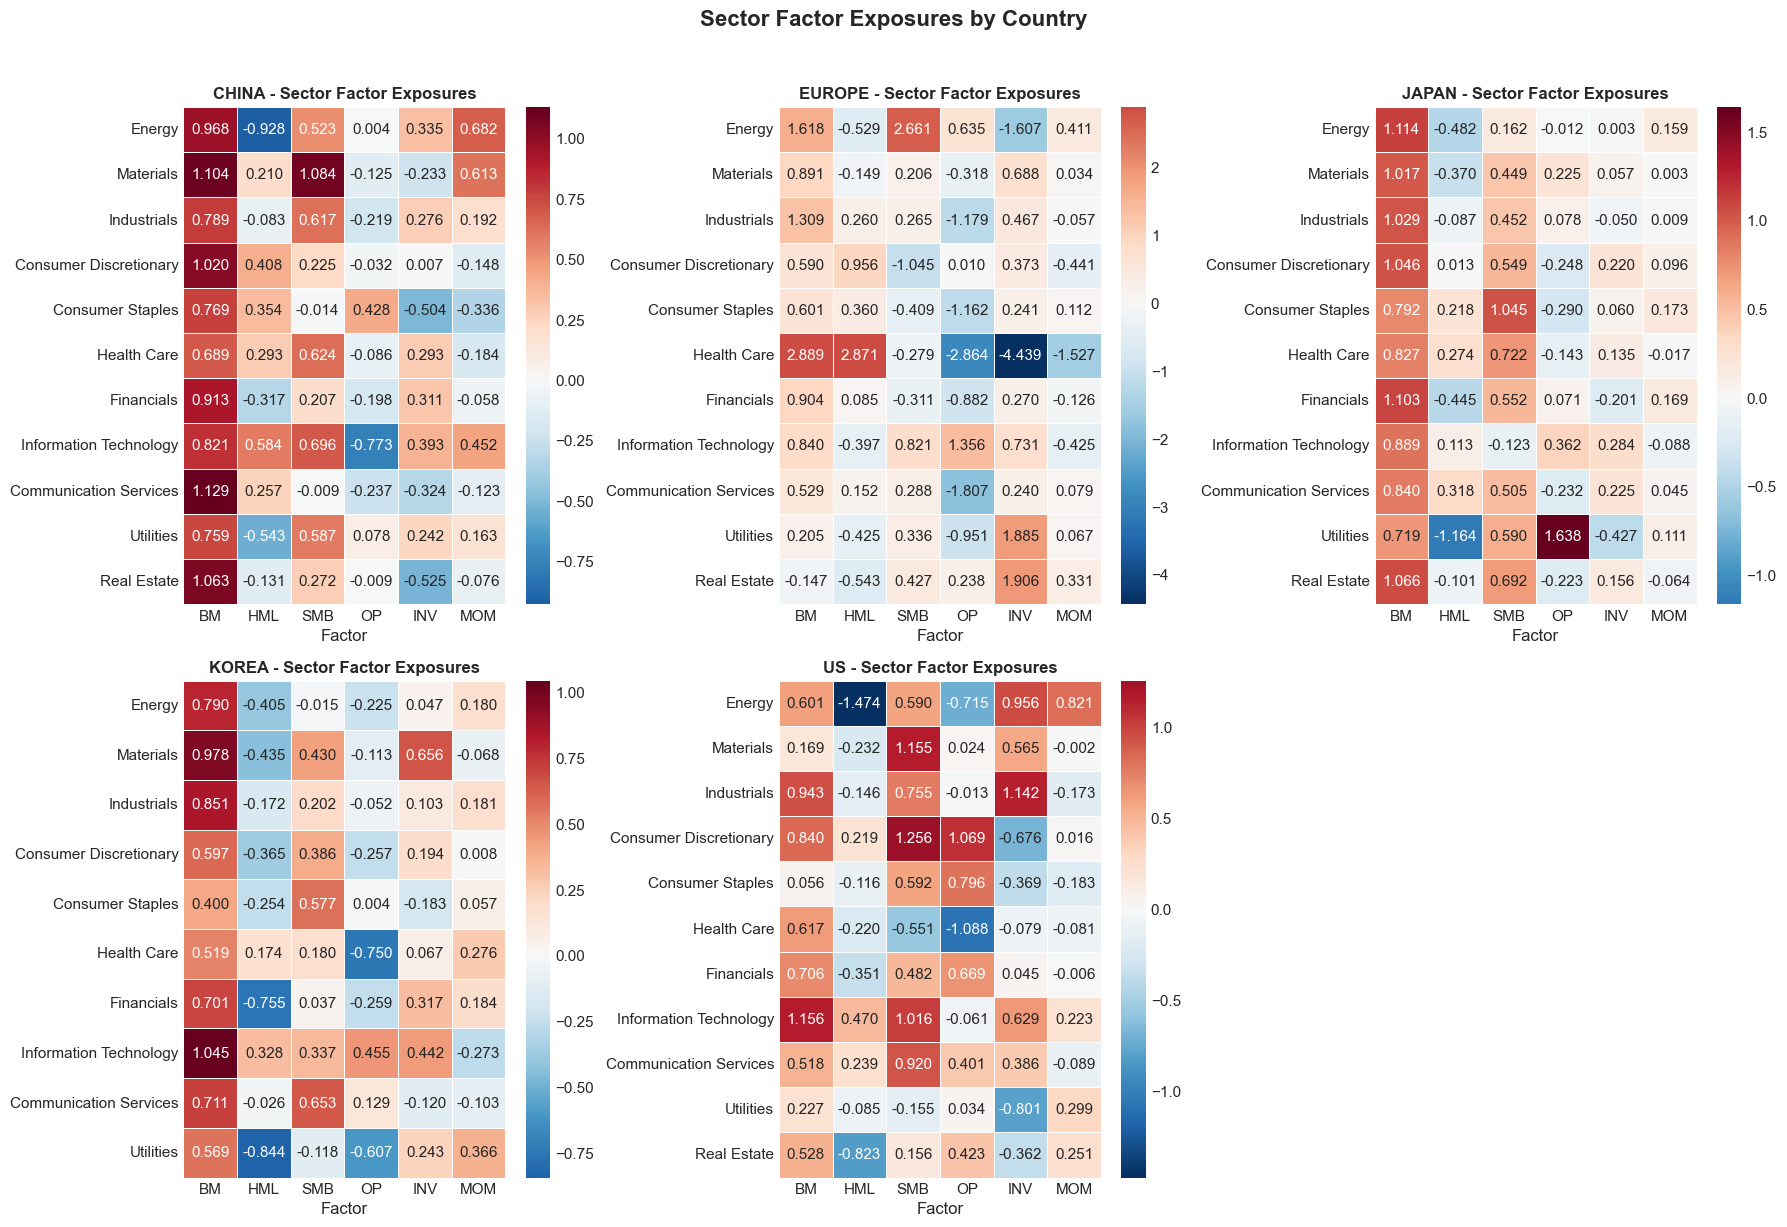

In [22]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['industry_ER'][country].copy()
    
    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')
    
    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]
    
    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]
        
        sns.heatmap(plot_data, annot=True, fmt='.3f', cmap='RdBu_r', 
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.3 Size Analysis

SIZE QUINTILE EXPECTED RETURNS


,CHINA,EUROPE,JAPAN,KOREA,US
size,,,,,
small,-0.0405,0.3511,0.2986,2.6787,0.2439
mid,0.3987,0.4622,0.5107,3.8450,0.0797
large,0.4355,0.5387,0.5817,4.3878,0.0394


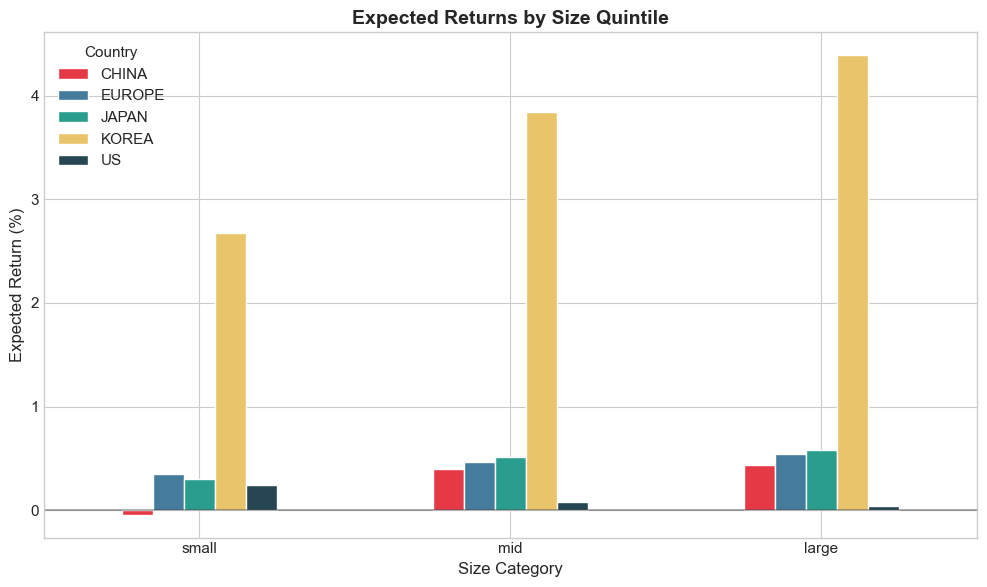

In [23]:
# Size quintile analysis
print("="*70)
print("SIZE QUINTILE EXPECTED RETURNS")
print("="*70)

size_comparison = pd.DataFrame()

for country in COUNTRIES:
    size_er = data['size_ER'][country].copy()
    if 'size' in size_er.columns and 'ER' in size_er.columns:
        size_er = size_er.set_index('size')
        size_comparison[country.upper()] = size_er['ER']

display(size_comparison.style.format('{:.4f}').background_gradient(cmap='RdYlGn', axis=None))

# Bar chart
fig, ax = plt.subplots(figsize=(10, 6))
size_comparison.plot(kind='bar', ax=ax, color=[COUNTRY_COLORS[c.lower()] for c in size_comparison.columns])
ax.set_title('Expected Returns by Size Quintile', fontsize=14, fontweight='bold')
ax.set_xlabel('Size Category')
ax.set_ylabel('Expected Return (%)')
ax.legend(title='Country')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 4. Cross-Country Comparison

### 4.1 Market Expected Returns

In [ ]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['wmean_ER'][country]
    market_er[country.upper()] = wmean.iloc[0, 1] if wmean.shape[1] > 1 else wmean.iloc[0, 0]

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] RAW MARKET ER - For reference only (different scales)")
print("-"*70)
display(market_er_df.style.format('{:.4f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_er = data['total_ER'][country]
    wmean = data['wmean_ER'][country]
    raw_er = wmean.iloc[0, 1] if wmean.shape[1] > 1 else wmean.iloc[0, 0]
    
    if 'ER' in total_er.columns:
        er_values = total_er['ER'].dropna()
        
        # What percentile is the market ER within its own distribution?
        market_percentile = (er_values < raw_er).mean() * 100
        
        # Z-score of market ER within country
        market_zscore = (raw_er - er_values.mean()) / er_values.std()
        
        # Percentage of stocks with positive ER
        pct_positive = (er_values > 0).mean() * 100
        
        # Spread between top and bottom quintile
        er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)
        
        # Sharpe-like metric: mean ER / std ER
        er_sharpe = er_values.mean() / er_values.std() if er_values.std() > 0 else 0
        
        comparable_metrics.append({
            'Country': country.upper(),
            'Market ER Percentile': market_percentile,
            'Market ER Z-Score': market_zscore,
            '% Stocks Positive ER': pct_positive,
            'ER Dispersion (Q80-Q20)': er_spread,
            'ER Sharpe (mean/std)': er_sharpe
        })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.4f}',
    'ER Sharpe (mean/std)': '{:.3f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = market weighted toward higher ER stocks")
print("  • % Stocks Positive ER: Higher = more bullish signal for that market")
print("  • ER Sharpe: Higher = more consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: % Positive ER
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: ER Sharpe
ax = axes[1]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: Market Percentile
ax = axes[2]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.2 Factor Premium Comparison

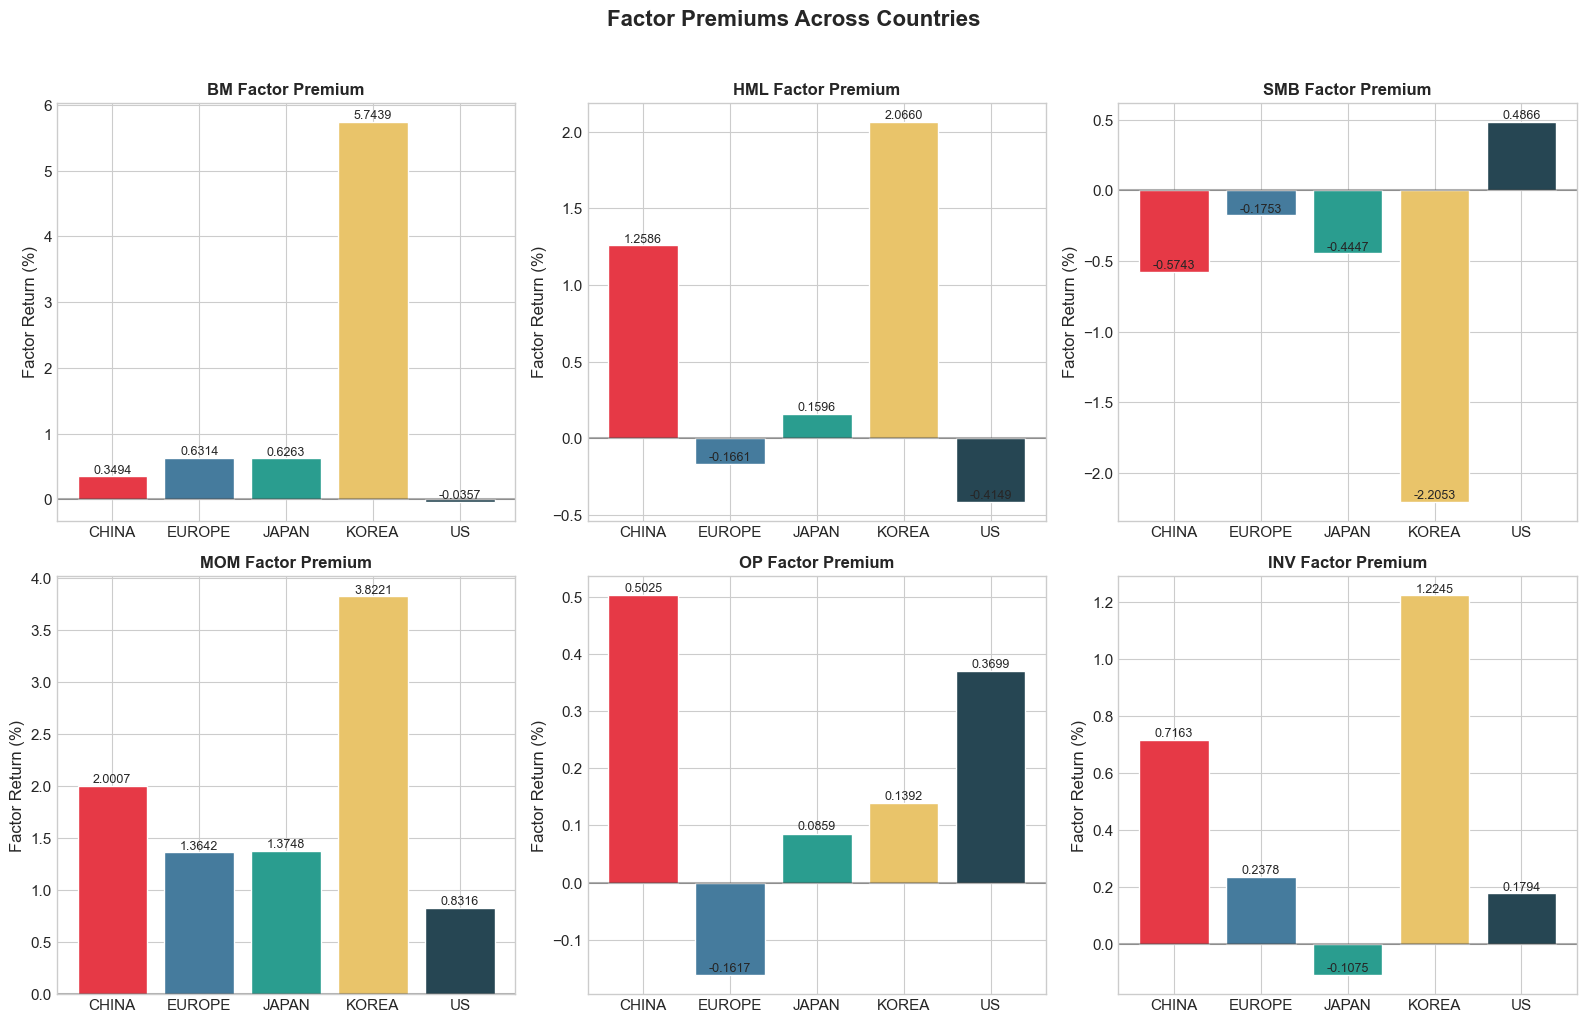

In [25]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []
    
    for country in COUNTRIES:
        fr = data['factor_result'][country].set_index('factor')
        if factor in fr.index:
            factor_vals.append(fr.loc[factor, 'factor_return'])
        else:
            factor_vals.append(0)
    
    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')
    
    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, 
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.3 Cross-Country Factor Correlation

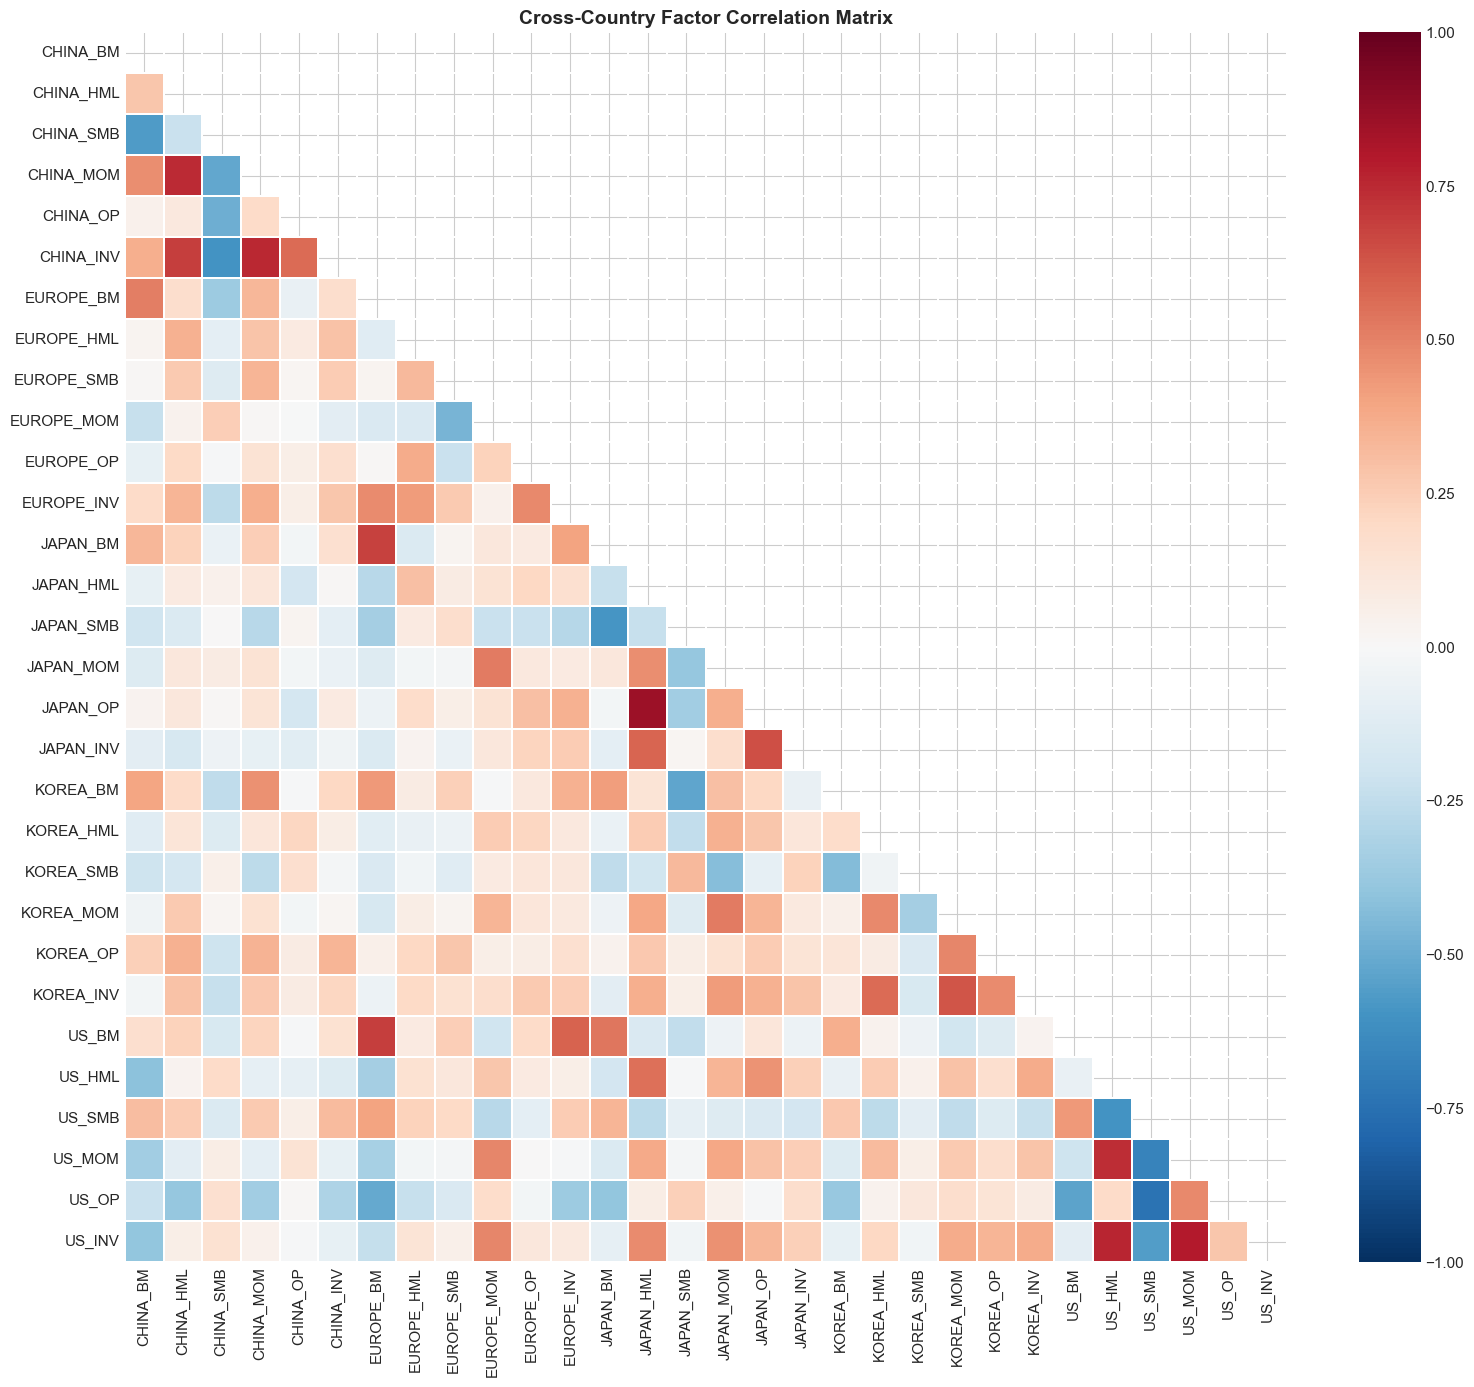

In [26]:
# Combine factor time series across countries for correlation analysis
combined_factors = pd.DataFrame()

for country in COUNTRIES:
    factor_ts = data['factor_ts'][country]
    for col in ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']:
        if col in factor_ts.columns:
            combined_factors[f'{country.upper()}_{col}'] = factor_ts[col].pct_change()

# Calculate correlation matrix
combined_corr = combined_factors.dropna().corr()

# Plot
fig, ax = plt.subplots(figsize=(16, 14))
mask = np.triu(np.ones_like(combined_corr, dtype=bool))
sns.heatmap(combined_corr, mask=mask, annot=False, cmap='RdBu_r', 
            center=0, ax=ax, vmin=-1, vmax=1, linewidths=0.1)
ax.set_title('Cross-Country Factor Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [27]:
# Same factor across different countries correlation
print("="*70)
print("SAME FACTOR CORRELATION ACROSS COUNTRIES")
print("="*70)

for factor in ['BM', 'MOM', 'SMB']:
    print(f"\n{factor} Factor:")
    factor_cols = [col for col in combined_factors.columns if col.endswith(f'_{factor}')]
    if factor_cols:
        corr_matrix = combined_factors[factor_cols].dropna().corr()
        corr_matrix.columns = [c.replace(f'_{factor}', '') for c in corr_matrix.columns]
        corr_matrix.index = [c.replace(f'_{factor}', '') for c in corr_matrix.index]
        display(corr_matrix.style.format('{:.3f}').background_gradient(cmap='RdYlGn', axis=None))

SAME FACTOR CORRELATION ACROSS COUNTRIES

BM Factor:


,CHINA,EUROPE,JAPAN,KOREA,US
CHINA,1.000,0.510,0.330,0.397,0.168
EUROPE,0.510,1.000,0.684,0.431,0.690
JAPAN,0.330,0.684,1.000,0.421,0.536
KOREA,0.397,0.431,0.421,1.000,0.361
US,0.168,0.690,0.536,0.361,1.000



MOM Factor:


,CHINA,EUROPE,JAPAN,KOREA,US
CHINA,1.000,0.010,0.146,0.150,-0.100
EUROPE,0.010,1.000,0.517,0.338,0.488
JAPAN,0.146,0.517,1.000,0.518,0.383
KOREA,0.150,0.338,0.518,1.000,0.262
US,-0.100,0.488,0.383,0.262,1.000



SMB Factor:


,CHINA,EUROPE,JAPAN,KOREA,US
CHINA,1.000,-0.132,0.003,0.057,-0.146
EUROPE,-0.132,1.000,0.179,-0.123,0.199
JAPAN,0.003,0.179,1.000,0.327,-0.087
KOREA,0.057,-0.123,0.327,1.000,-0.102
US,-0.146,0.199,-0.087,-0.102,1.000


### 4.4 Sector Dispersion Analysis

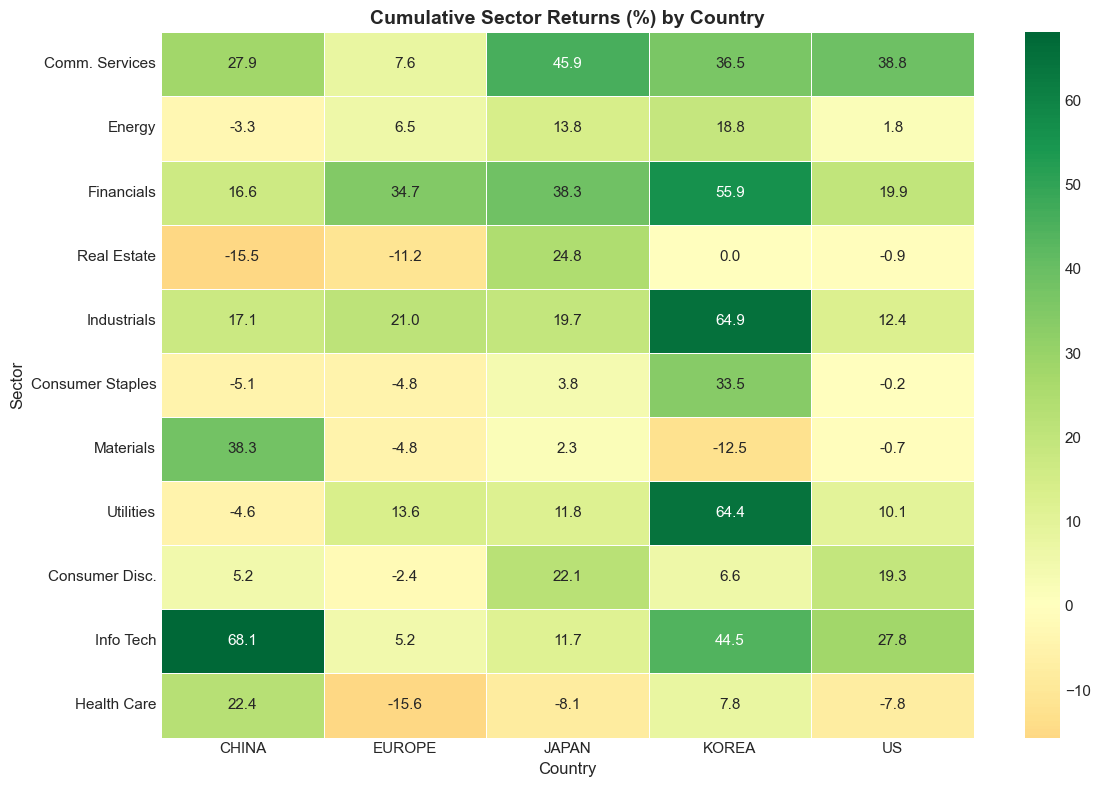

In [28]:
# Sector performance dispersion
def get_sector_returns(sector_ts):
    """Calculate total returns for sectors"""
    return ((sector_ts.iloc[-1] / sector_ts.iloc[0]) - 1) * 100

sector_returns_all = pd.DataFrame()

for country in COUNTRIES:
    sector_ts = data['sector_ts'][country]
    sector_rets = get_sector_returns(sector_ts)
    sector_rets.index = [SECTOR_NAMES.get(str(i), str(i)) for i in sector_rets.index]
    sector_returns_all[country.upper()] = sector_rets

# Heatmap
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(sector_returns_all, annot=True, fmt='.1f', cmap='RdYlGn', 
            center=0, ax=ax, linewidths=0.5)
ax.set_title('Cumulative Sector Returns (%) by Country', fontsize=14, fontweight='bold')
ax.set_xlabel('Country')
ax.set_ylabel('Sector')
plt.tight_layout()
plt.show()

---
## 5. Market Interpretation & Key Insights

In [ ]:
# Generate comprehensive market summary WITH NORMALIZED METRICS
def generate_market_summary(country):
    """Generate comprehensive summary for a country with normalized metrics"""
    summary = {}
    
    # Stock count
    summary['Total Stocks'] = len(data['total_ER'][country])
    
    # Market ER (raw - for reference)
    wmean = data['wmean_ER'][country]
    raw_er = wmean.iloc[0, 1] if wmean.shape[1] > 1 else wmean.iloc[0, 0]
    summary['Raw ER (%)'] = raw_er
    
    # Normalized metrics
    total_er = data['total_ER'][country]
    if 'ER' in total_er.columns:
        er_values = total_er['ER'].dropna()
        summary['% Positive ER'] = (er_values > 0).mean() * 100
        summary['ER Sharpe'] = er_values.mean() / er_values.std() if er_values.std() > 0 else 0
    
    # Best factor (within country)
    fr = data['factor_result'][country].set_index('factor')['factor_return']
    summary['Best Factor'] = fr.idxmax()
    summary['Worst Factor'] = fr.idxmin()
    
    # Factor z-scores
    fr_norm = normalized_data['factor_result'][country].set_index('factor')
    summary['Best Factor Z'] = fr_norm['return_zscore'].max()
    summary['Worst Factor Z'] = fr_norm['return_zscore'].min()
    
    return summary

# Create summary table with normalized metrics
market_summary = pd.DataFrame({c.upper(): generate_market_summary(c) for c in COUNTRIES}).T

print("="*90)
print("COMPREHENSIVE MARKET SUMMARY (With Normalized Metrics)")
print("="*90)
print("\n⚠️  Use '% Positive ER' and 'ER Sharpe' for cross-country market comparison")
print("    (Raw ER values are NOT comparable across countries)\n")

display(market_summary.style.format({
    'Total Stocks': '{:.0f}',
    'Raw ER (%)': '{:.4f}',
    '% Positive ER': '{:.1f}',
    'ER Sharpe': '{:.3f}',
    'Best Factor Z': '{:.2f}',
    'Worst Factor Z': '{:.2f}'
}))

# Market ranking using NORMALIZED metrics
print("\n" + "="*70)
print("MARKET RANKING (Using Comparable Metrics)")
print("="*70)

# Composite score using normalized metrics
market_scores = []
for country in COUNTRIES:
    total_er = data['total_ER'][country]
    if 'ER' in total_er.columns:
        er_values = total_er['ER'].dropna()
        pct_positive = (er_values > 0).mean() * 100
        er_sharpe = er_values.mean() / er_values.std() if er_values.std() > 0 else 0
        
        # Composite score (weighted combination of normalized metrics)
        composite = (pct_positive - 50) / 50 * 0.5 + er_sharpe * 10 * 0.5
        
        market_scores.append({
            'Country': country.upper(),
            '% Positive ER': pct_positive,
            'ER Sharpe': er_sharpe,
            'Composite Score': composite
        })

score_df = pd.DataFrame(market_scores).sort_values('Composite Score', ascending=False)
print("\nRanking based on normalized signal strength:\n")
for i, row in score_df.iterrows():
    rank = list(score_df['Country']).index(row['Country']) + 1
    signal = "BULLISH" if row['Composite Score'] > 0.1 else ("BEARISH" if row['Composite Score'] < -0.1 else "NEUTRAL")
    print(f"  {rank}. {row['Country']:8} | +ER: {row['% Positive ER']:.1f}% | Sharpe: {row['ER Sharpe']:.3f} | {signal}")

In [ ]:
# Key findings interpretation WITH NORMALIZED METRICS
print("\n" + "="*90)
print("KEY FINDINGS & MARKET INTERPRETATION")
print("="*90)
print("\n⚠️  All cross-country comparisons use NORMALIZED metrics (Z-Score, Percentile)")
print("    for valid comparison across different factor model scales.\n")

# Factor analysis using Z-scores
print("[FACTOR ANALYSIS - Using Z-Score for Within-Country Strength]")
print("-" * 70)

for country in COUNTRIES:
    fr_norm = normalized_data['factor_result'][country]
    best_idx = fr_norm['return_zscore'].idxmax()
    worst_idx = fr_norm['return_zscore'].idxmin()
    best = fr_norm.loc[best_idx]
    worst = fr_norm.loc[worst_idx]
    print(f"{country.upper():8} | Best: {best['factor']:5} (Z:{best['return_zscore']:+.2f}) | Worst: {worst['factor']:5} (Z:{worst['return_zscore']:+.2f})")

# Cross-country insights using normalized z-scores
print("\n[CROSS-COUNTRY FACTOR INSIGHTS - Average Z-Score]")
print("-" * 70)

# Calculate average z-score for each factor across countries
avg_factor_z = {}
for factor in ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']:
    zscores = []
    for country in COUNTRIES:
        fr_norm = normalized_data['factor_result'][country]
        if factor in fr_norm['factor'].values:
            z = fr_norm[fr_norm['factor'] == factor]['return_zscore'].values[0]
            zscores.append(z)
    if zscores:
        avg_factor_z[factor] = np.mean(zscores)

avg_factor_z = pd.Series(avg_factor_z).sort_values(ascending=False)
print("\nFactors ranked by global consistency (Avg Z-Score):")
for factor, z in avg_factor_z.items():
    consistency = "STRONG" if z > 0.3 else ("WEAK" if z < -0.3 else "MIXED")
    print(f"  {factor:5}: {z:+.2f} -> {consistency}")

# Market attractiveness using normalized metrics
print("\n[MARKET ATTRACTIVENESS - Using Normalized Metrics]")
print("-" * 70)

market_ranking = []
for country in COUNTRIES:
    total_er = data['total_ER'][country]
    er_values = total_er['ER'].dropna() if 'ER' in total_er.columns else pd.Series([0])
    pct_positive = (er_values > 0).mean() * 100
    er_sharpe = er_values.mean() / er_values.std() if er_values.std() > 0 else 0
    market_ranking.append({
        'Country': country.upper(),
        '% Positive ER': pct_positive,
        'ER Sharpe': er_sharpe
    })

market_df = pd.DataFrame(market_ranking).sort_values('ER Sharpe', ascending=False)
print("\nMarkets ranked by signal strength (ER Sharpe):")
for i, (_, row) in enumerate(market_df.iterrows(), 1):
    signal = "BULLISH" if row['ER Sharpe'] > 0.05 else ("BEARISH" if row['ER Sharpe'] < -0.05 else "NEUTRAL")
    print(f"  {i}. {row['Country']:8}: Sharpe={row['ER Sharpe']:.3f}, +ER={row['% Positive ER']:.1f}% -> {signal}")

### 5.1 Detailed Country Analysis

In [36]:
def detailed_country_analysis(country):
    """Generate detailed analysis for a specific country"""
    print(f"\n{'='*80}")
    print(f"  {country.upper()} MARKET DETAILED ANALYSIS")
    print(f"{'='*41}")
    
    # Basic stats
    total_er = data['total_ER'][country]
    print(f"\n[MARKET OVERVIEW]")
    print(f"  Total Stocks: {len(total_er):,}")
    print(f"  Date Range: {data['factor_ts'][country].index.min().strftime('%Y-%m-%d')} to {data['factor_ts'][country].index.max().strftime('%Y-%m-%d')}")
    
    # Factor returns
    print(f"\n[FACTOR RETURNS]")
    fr = data['factor_result'][country].set_index('factor')['factor_return']
    for factor, ret in fr.sort_values(ascending=False).items():
        bar = '+' * int(abs(ret) * 20) if ret > 0 else '-' * int(abs(ret) * 20)
        print(f"  {factor:5}: {ret:+.4f} {bar}")
    
    # Sector analysis
    print(f"\n[SECTOR EXPECTED RETURNS]")
    ind_er = data['industry_ER'][country]
    if 'Sector' in ind_er.columns and 'ER' in ind_er.columns:
        for _, row in ind_er.nlargest(5, 'ER').iterrows():
            print(f"  {row['Sector']:25}: {row['ER']:+.4f}")
    
    # Top stocks
    print(f"\n[TOP 5 STOCKS BY EXPECTED RETURN]")
    top = data['top_bot'][country].nlargest(5, 'ER')
    for _, row in top.iterrows():
        print(f"  {row['instrument']:12} | ER: {row['ER']:+.4f} | Sharpe: {row['Sharpe']:.2f}")
    
    # Bottom stocks
    print(f"\n[BOTTOM 5 STOCKS BY EXPECTED RETURN]")
    bottom = data['top_bot'][country].nsmallest(5, 'ER')
    for _, row in bottom.iterrows():
        print(f"  {row['instrument']:12} | ER: {row['ER']:+.4f} | Sharpe: {row['Sharpe']:.2f}")

# Run detailed analysis for each country
for country in COUNTRIES:
    detailed_country_analysis(country)


  CHINA MARKET DETAILED ANALYSIS

[MARKET OVERVIEW]
  Total Stocks: 557
  Date Range: 2025-02-07 to 2026-01-30

[FACTOR RETURNS]
  MOM  : +2.0007 ++++++++++++++++++++++++++++++++++++++++
  HML  : +1.2586 +++++++++++++++++++++++++
  INV  : +0.7163 ++++++++++++++
  OP   : +0.5025 ++++++++++
  BM   : +0.3494 ++++++
  SMB  : -0.5743 -----------

[SECTOR EXPECTED RETURNS]
  Materials                : +0.8476
  Information Technology   : +0.6116
  Communication Services   : +0.4451
  Health Care              : +0.1496
  Industrials              : +0.1052

[TOP 5 STOCKS BY EXPECTED RETURN]
  CNE1000020V4 | ER: +3.4611 | Sharpe: 0.17
  HK0000218211 | ER: +3.4173 | Sharpe: 0.14
  CNE100002CC3 | ER: +3.0973 | Sharpe: 0.15
  CNE100004413 | ER: +3.0554 | Sharpe: 0.14
  CA16890P1036 | ER: +3.0133 | Sharpe: 0.19

[BOTTOM 5 STOCKS BY EXPECTED RETURN]
  CNE100000V20 | ER: -1.2866 | Sharpe: -0.15
  CNE0000000T2 | ER: -1.1180 | Sharpe: -0.16
  CNE100004090 | ER: -1.0001 | Sharpe: -0.15
  CNE100000HB8 |

### 5.2 Investment Opportunities Summary

In [ ]:
print("\n" + "="*90)
print("INVESTMENT OPPORTUNITIES (Using Normalized Comparisons)")
print("="*90)

# Best factor plays by country (using z-score for within-country strength)
print("\n[1] BEST FACTOR STRATEGIES BY COUNTRY")
print("-"*70)
print("(Showing factors with highest z-score within each country)\n")

for country in COUNTRIES:
    fr_norm = normalized_data['factor_result'][country]
    best_idx = fr_norm['return_zscore'].idxmax()
    best_row = fr_norm.loc[best_idx]
    raw_return = data['factor_result'][country].set_index('factor').loc[best_row['factor'], 'factor_return']
    print(f"  {country.upper():8}: {best_row['factor']:5} (Z: {best_row['return_zscore']:+.2f}, Raw: {raw_return:+.4f}%)")

# Top sectors using Z-SCORE (comparable across countries)
print("\n[2] TOP SECTORS BY NORMALIZED SCORE (Z-Score)")
print("-"*70)
print("(Sectors ranked by z-score within their country - comparable across markets)\n")

all_sectors_normalized = []
for country in COUNTRIES:
    ind_er = normalized_data['industry_ER'][country]
    if 'Sector' in ind_er.columns and 'ER_zscore' in ind_er.columns:
        for _, row in ind_er.iterrows():
            all_sectors_normalized.append({
                'Country': country.upper(),
                'Sector': row['Sector'],
                'Z-Score': row['ER_zscore'],
                'Percentile': row['ER_percentile'],
                'Raw ER': row['ER']
            })

all_sectors_df = pd.DataFrame(all_sectors_normalized)
top_sectors_norm = all_sectors_df.nlargest(10, 'Z-Score')

for _, row in top_sectors_norm.iterrows():
    print(f"  {row['Country']:8} | {row['Sector']:25} | Z: {row['Z-Score']:+.2f} | Pctl: {row['Percentile']:.0f}")

# Top stocks - WITHIN-COUNTRY percentile ranking
print("\n[3] TOP STOCKS BY PERCENTILE RANK (Within-Country)")
print("-"*70)
print("(Shows top stocks by percentile rank within their country - comparable across markets)\n")

all_stocks_normalized = []
for country in COUNTRIES:
    total_er = normalized_data['total_ER'][country]
    top_stocks = total_er.nlargest(10, 'ER_percentile')
    
    for _, row in top_stocks.iterrows():
        all_stocks_normalized.append({
            'Country': country.upper(),
            'Ticker': row.get('instrument', 'N/A'),
            'Percentile': row.get('ER_percentile', 0),
            'Z-Score': row.get('ER_zscore', 0),
            'Raw ER': row.get('ER', 0),
            'Sharpe': row.get('Sharpe', 0)
        })

all_stocks_df = pd.DataFrame(all_stocks_normalized)

# Show top 3 from each country for fair representation
print("Top 3 stocks from each country (by percentile rank):\n")
for country in COUNTRIES:
    country_stocks = all_stocks_df[all_stocks_df['Country'] == country.upper()].nlargest(3, 'Percentile')
    print(f"  {country.upper()}:")
    for _, row in country_stocks.iterrows():
        print(f"    {row['Ticker']:15} | Pctl: {row['Percentile']:.1f} | Z: {row['Z-Score']:+.2f} | Sharpe: {row['Sharpe']:.2f}")
    print()

# Global top stocks by Z-score
global_top = all_stocks_df.nlargest(10, 'Z-Score')
print("\n[4] GLOBAL TOP 10 STOCKS (By Z-Score)")
print("-"*70)
for _, row in global_top.iterrows():
    print(f"  {row['Country']:6} | {row['Ticker']:15} | Z: {row['Z-Score']:+.2f} | Pctl: {row['Percentile']:.1f}")

### 5.3 Risk Considerations

In [38]:
# Risk analysis
print("\n" + "="*90)
print("RISK CONSIDERATIONS")
print("="*90)

# Factor volatility comparison
print("\n[FACTOR VOLATILITY BY COUNTRY (Annualized %)]")
print("-"*60)

factor_vol = pd.DataFrame()
for country in COUNTRIES:
    returns = data['factor_ts'][country].pct_change().dropna()
    vol = returns.std() * np.sqrt(52) * 100
    factor_vol[country.upper()] = vol

display(factor_vol.T.style.format('{:.2f}').background_gradient(cmap='YlOrRd', axis=None))

# Maximum drawdowns
print("\n[MAXIMUM FACTOR DRAWDOWNS (%)]")
print("-"*60)

factor_dd = pd.DataFrame()
for country in COUNTRIES:
    ts = data['factor_ts'][country]
    dd = ((ts / ts.cummax()) - 1).min() * 100
    factor_dd[country.upper()] = dd

display(factor_dd.T.style.format('{:.1f}').background_gradient(cmap='RdYlGn', axis=None))


RISK CONSIDERATIONS

[FACTOR VOLATILITY BY COUNTRY (Annualized %)]
------------------------------------------------------------


,BM,HML,SMB,MOM,OP,INV,REV
CHINA,14.40,18.78,9.34,16.45,10.70,13.72,16.94
EUROPE,13.61,9.83,6.24,12.85,5.95,7.16,9.53
JAPAN,16.66,13.94,8.31,11.16,9.17,6.06,11.60
KOREA,21.56,24.06,14.32,26.74,17.68,11.58,20.94
US,17.34,11.67,14.94,17.71,13.85,9.02,13.56



[MAXIMUM FACTOR DRAWDOWNS (%)]
------------------------------------------------------------


,BM,HML,SMB,MOM,OP,INV,REV
CHINA,-9.7,-15.4,-12.2,-11.1,-5.4,-9.3,-33.7
EUROPE,-11.9,-29.2,-8.4,-5.0,-5.9,-5.6,-14.2
JAPAN,-12.2,-28.2,-11.1,-10.9,-14.1,-15.9,-16.2
KOREA,-8.8,-25.0,-28.3,-13.0,-21.4,-5.3,-26.7
US,-17.7,-15.3,-12.5,-16.9,-21.6,-10.6,-18.2


---
## 6. Current Market News & Interpretation

This section fetches real-time market news and interprets our factor/sector findings in the context of current market conditions.

In [46]:
# Web Search & LLM-based News Analysis
# Requires: pip install duckduckgo-search anthropic openai

import os
from datetime import datetime, timedelta
from typing import Dict, List, Optional
import json
import configparser

# ============================================================================
# CONFIGURATION - Set your API keys here or via environment variables
# ============================================================================
config = configparser.ConfigParser()
config.read(r'D:/config.ini')
OPENAI_API_KEY = config.get('openai', 'API_KEY')

# Choose LLM provider: 'anthropic' or 'openai'
LLM_PROVIDER = 'openai'

# ============================================================================
# Web Search Functions
# ============================================================================

def search_duckduckgo(query: str, max_results: int = 10) -> List[Dict]:
    """Search using DuckDuckGo (free, no API key needed)"""
    try:
        from ddgs import DDGS
        results = []
        with DDGS(verify=False) as ddgs:
            for r in ddgs.news(query, max_results=max_results):
                results.append({
                    'title': r.get('title', ''),
                    'body': r.get('body', ''),
                    'url': r.get('url', ''),
                    'date': r.get('date', ''),
                    'source': r.get('source', '')
                })
        return results
    except ImportError:
        print("DuckDuckGo search not available. Install with: pip install duckduckgo-search")
        return []
    except Exception as e:
        print(f"DuckDuckGo search error: {e}")
        return []

def search_news(query: str, max_results: int = 8) -> List[Dict]:
    """Search news using available methods"""
    # Fall back to DuckDuckGo
    return search_duckduckgo(query, max_results)

# ============================================================================
# LLM Analysis Functions
# ============================================================================
def analyze_with_openai(news_data: str, analysis_prompt: str) -> str:
    """Analyze news using OpenAI GPT"""
    try:
        from openai import OpenAI
        client = OpenAI(api_key=OPENAI_API_KEY)
        
        response = client.responses.create(
            model="gpt-5-mini-2025-08-07",
            input=[
                {
                    "role": "user",
                    "content": f"{analysis_prompt}\n\nNews Data:\n{news_data}"
                }
            ],
            tools=[{'type':'web_search'}]
        )
        print(response)
        return response.text
    except Exception as e:
        return f"OpenAI API error: {e}"

def analyze_with_llm(news_data: str, analysis_prompt: str) -> str:
    """Analyze news using configured LLM provider"""
    return analyze_with_openai(news_data, analysis_prompt)

print("Web Search & LLM Analysis module loaded.")
print(f"LLM Provider: {LLM_PROVIDER}")

Web Search & LLM Analysis module loaded.
LLM Provider: openai


### 6.1 Fetch Market News via Web Search

In [8]:
# Fetch market news for each country using web search
print("="*90)
print("FETCHING CURRENT MARKET NEWS VIA WEB SEARCH")
print("="*90)
print(f"Fetch time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

# Define search queries for each market
MARKET_QUERIES = {
    'china': 'China stock market CSI Shanghai Hang Seng latest news',
    'europe': 'European stocks STOXX 600 DAX FTSE market news',
    'japan': 'Japan Nikkei Topix stock market BOJ latest news',
    'korea': 'South Korea KOSPI stock market Samsung latest news',
    'us': 'US stock market S&P 500 NASDAQ Wall Street latest news'
}

# Fetch news for each market
market_news = {}
all_news_text = {}

for market, query in MARKET_QUERIES.items():
    print(f"\nSearching: {market.upper()}...")
    news = search_news(query, max_results=8)
    market_news[market] = news
    
    # Compile news text for LLM analysis
    news_text = f"\n=== {market.upper()} MARKET NEWS ===\n"
    for i, article in enumerate(news, 1):
        news_text += f"\n{i}. {article['title']}\n"
        news_text += f"   Source: {article['source']} | Date: {article['date']}\n"
        news_text += f"   {article['body'][:300]}...\n"
    all_news_text[market] = news_text
    
    print(f"  Found {len(news)} articles")
    for article in news[:3]:
        print(f"  • {article['title'][:70]}...")

print(f"\nTotal articles fetched: {sum(len(v) for v in market_news.values())}")

FETCHING CURRENT MARKET NEWS VIA WEB SEARCH
Fetch time: 2026-02-05 17:54:30


Searching: CHINA...
  Found 8 articles
  • Commodities carnage spills into Asian equities, Shanghai posts biggest...
  • Upbeat China industrial profit data lifts Hong Kong stocks to fifth da...
  • MCHI: Capitalizing On Positive China Market Momentum...

Searching: EUROPE...
  Found 8 articles
  • European stocks end flat as UK mining giants rise on metals rebound...
  • U.S. Futures, European Stocks Mixed as Markets Await ECB and BOE Rate ...
  • European stock markets close Tuesday mixed...

Searching: JAPAN...
  Found 8 articles
  • Japan's Nikkei advances, bond futures slip after BOJ holds rates stead...
  • Nikkei 225: Unraveling Japan's Premier Stock Index...
  • Asia markets mostly advance as Bank of Japan leaves interest rates on ...

Searching: KOREA...
  Found 8 articles
  • As US stock market wobbles, this Asian market knocks it out of the bal...
  • Selloff in South Korean Stocks Prompts Brief Tr

In [9]:
# Fetch factor and sector-specific news
print("="*90)
print("FETCHING SECTOR NEWS")
print("="*90)

# Sector-specific queries
SECTOR_QUERIES = {
    'Energy': 'energy stocks oil prices OPEC crude petroleum',
}

# Find top sector & industries from data
top_sectors = sector_er_comparison.mean(axis=1).nlargest(3).index.tolist()
for sector in top_sectors:
    SECTOR_QUERIES[sector] = f"{sector} sector stocks market news"

# Fetch sector news  
sector_news = {}
print("\nFetching sector news...")
for sector, query in SECTOR_QUERIES.items():
    print(f"  Searching: {sector}...")
    news = search_news(query, max_results=5)
    sector_news[sector] = news
    print(f"    Found {len(news)} articles")

print("\nNews fetching complete!")

FETCHING FACTOR & SECTOR NEWS

Fetching factor-related news...
  Searching: MOM...
    Found 5 articles
  Searching: BM...
    Found 5 articles
  Searching: SMB...
    Found 5 articles
  Searching: OP...
    Found 5 articles
  Searching: INV...
    Found 5 articles

Fetching sector news...
  Searching: Energy...
    Found 5 articles
  Searching: Info Tech...
    Found 5 articles
  Searching: Financials...
    Found 5 articles
  Searching: Health Care...
    Found 5 articles
  Searching: Materials...
    Found 5 articles

News fetching complete!


### 6.2 LLM Analysis: Factor Performance vs News

In [51]:
# LLM Analysis of Factor News with Our Data
print("="*90)
print("LLM ANALYSIS: FACTOR PERFORMANCE VS NEWS")
print("="*90)

# Prepare factor performance data
factor_perf_summary = "FACTOR PERFORMANCE DATA:\n"
for country in COUNTRIES:
    fr = data['factor_result'][country].set_index('factor')['factor_return']
    factor_perf_summary += f"\n{country.upper()}:\n"
    for factor, ret in fr.items():
        factor_perf_summary += f"  {factor}: {ret:+.4f}%\n"

# Prepare factor news
factor_news_summary = "\nRECENT FACTOR-RELATED NEWS:\n"
for factor, news in factor_news.items():
    factor_news_summary += f"\n=== {factor} Factor ===\n"
    for article in news[:3]:
        factor_news_summary += f"• {article['title']}\n  {article['body'][:1000]}...\n"

# LLM Analysis Prompt
factor_analysis_prompt = """You are a quantitative finance analyst. Analyze the relationship between the factor performance data and recent news.

For each factor (MOM, BM, SMB, OP, INV):
1. Summarize the current performance across markets
2. Identify news themes that explain the performance
3. Provide a forward-looking assessment (bullish/bearish/neutral)
4. Give specific actionable recommendations

Be concise but insightful. Focus on the connection between news events and factor returns.
Format your response with clear headers for each factor."""

print("\nAnalyzing with LLM...")
'''factor_llm_analysis = analyze_with_llm(
    factor_perf_summary + factor_news_summary,
    factor_analysis_prompt
)'''

print("\n" + "-"*80)
print("FACTOR ANALYSIS RESULTS")
print("-"*80)
#print(factor_llm_analysis)

LLM ANALYSIS: FACTOR PERFORMANCE VS NEWS

Analyzing with LLM...

--------------------------------------------------------------------------------
FACTOR ANALYSIS RESULTS
--------------------------------------------------------------------------------


In [52]:
factor_news_summary

'\nRECENT FACTOR-RELATED NEWS:\n\n=== MOM Factor ===\n• What 2025 Taught Investors About Chipotle Stock\n  Don\'t miss the latest top 10 list, available with Stock Advisor, and join an investing community built by individual investors for individual......\n• Fast-paced Momentum Stock Ford Motor (F) Is Still Trading at a Bargain\n  Ford Motor (F) could be a great choice for investors looking to buy stocks that have gained strong......\n• AMD stock falls 8% despite modest beat as Raymond James notes investor concerns...\n  Advanced Micro Devices (NASDAQ:AMD) stock dropped approximately 8% in after-hours trading following ......\n\n=== BM Factor ===\n• Should Value Investors Buy Allianz (ALIZY) Stock?\n  Here at Zacks, our focus is on the proven Zacks Rank system, which emphasizes earnings estimates and estimate revisions to find great stocks .......\n• Is Nomura (NMR) a Great Value Stock Right Now?\n  Here at Zacks, our focus is on the proven Zacks Rank system, which emphasizes earnings 

### 6.3 LLM Analysis: Sector Performance vs News

In [ ]:
# LLM Analysis of Sector News with Our Data
print("="*90)
print("LLM ANALYSIS: SECTOR PERFORMANCE VS NEWS")
print("="*90)

# Prepare sector performance data
sector_perf_summary = "SECTOR EXPECTED RETURNS DATA:\n"
sector_perf_summary += sector_er_comparison.to_string()

# Prepare sector news
sector_news_summary = "\n\nRECENT SECTOR NEWS:\n"
for sector, news in sector_news.items():
    sector_news_summary += f"\n=== {sector} ===\n"
    for article in news[:3]:
        sector_news_summary += f"• {article['title']}\n  {article['body'][:200]}...\n"

# LLM Analysis Prompt
sector_analysis_prompt = """You are a sector rotation strategist. Analyze the sector expected returns data alongside recent sector news.

Provide:
1. SECTOR RANKINGS: Rank sectors by attractiveness based on ER data and news sentiment
2. ROTATION SIGNALS: Identify sectors to overweight, underweight, or avoid
3. NEWS CATALYSTS: Key news events that could drive sector performance
4. CROSS-MARKET INSIGHTS: Note if certain sectors are strong/weak across multiple markets
5. ACTIONABLE TRADES: Specific sector allocation recommendations

Be direct and actionable. Focus on identifying opportunities and risks."""

print("\nAnalyzing with LLM...")
sector_llm_analysis = analyze_with_llm(
    sector_perf_summary + sector_news_summary,
    sector_analysis_prompt
)

print("\n" + "-"*80)
print("SECTOR ANALYSIS RESULTS")
print("-"*80)
print(sector_llm_analysis)

### 6.4 LLM Analysis: Comprehensive Market Interpretation

In [ ]:
# Comprehensive LLM Market Interpretation for Each Country
print("="*90)
print("LLM ANALYSIS: COMPREHENSIVE MARKET INTERPRETATION")
print("="*90)

market_interpretations = {}

for country in COUNTRIES:
    print(f"\n{'='*60}")
    print(f"Analyzing {country.upper()} market...")
    print("="*60)
    
    # Prepare country-specific data
    fr = data['factor_result'][country].set_index('factor')['factor_return']
    wmean = data['wmean_ER'][country]
    market_er = wmean.iloc[0, 1] if wmean.shape[1] > 1 else wmean.iloc[0, 0]
    
    # Size data
    size_er = data['size_ER'][country]
    
    # Industry data
    ind_er = data['industry_ER'][country]
    
    # Top/Bottom stocks
    top_stocks = data['top_bot'][country].nlargest(5, 'ER')[['instrument', 'ER', 'Sharpe']]
    bot_stocks = data['top_bot'][country].nsmallest(5, 'ER')[['instrument', 'ER', 'Sharpe']]
    
    country_data = f"""
=== {country.upper()} MARKET DATA ===

MARKET EXPECTED RETURN: {market_er:+.4f}%

FACTOR RETURNS:
{fr.to_string()}

SIZE ANALYSIS:
{size_er.to_string()}

TOP SECTORS:
{ind_er.nlargest(5, 'ER')[['Sector', 'ER']].to_string() if 'Sector' in ind_er.columns else ind_er.nlargest(5, 'ER').to_string()}

TOP 5 STOCKS:
{top_stocks.to_string()}

BOTTOM 5 STOCKS:
{bot_stocks.to_string()}
"""
    
    # Add news for this country
    country_news = all_news_text.get(country, "No news available")
    
    # LLM prompt for country analysis
    country_prompt = f"""You are a senior equity strategist providing analysis on the {country.upper()} stock market.

Based on the quantitative data and recent news, provide:

1. MARKET OUTLOOK: Overall assessment (bullish/bearish/neutral) with conviction level
2. KEY DRIVERS: What's driving the market based on factor performance and news
3. FACTOR STRATEGY: Which factors to emphasize in this market
4. SECTOR POSITIONING: Top 3 sectors to overweight and why
5. STOCK IDEAS: Commentary on the top/bottom stocks shown
6. RISKS: Key risks to monitor
7. RECOMMENDATION: Specific allocation recommendation (overweight/neutral/underweight vs global)

Be specific and actionable. Reference the actual data provided."""

    analysis = analyze_with_llm(country_data + "\n\nRECENT NEWS:\n" + country_news, country_prompt)
    market_interpretations[country] = analysis
    
    print(analysis)
    print("\n" + "-"*60)

In [ ]:
# Final LLM Analysis: Global Investment Strategy (WITH NORMALIZED DATA)
print("="*90)
print("LLM ANALYSIS: GLOBAL INVESTMENT STRATEGY")
print("="*90)

# Compile normalized data for final analysis
global_summary = """
=== GLOBAL MARKET SUMMARY ===

IMPORTANT NOTE ON DATA:
Raw ER values have DIFFERENT SCALES across countries due to different factor model calibrations.
For cross-country comparisons, use NORMALIZED METRICS:
- Z-Score: Standardized (0 = country average, +1 = 1 std above)
- Percentile: Rank within country (100 = top)
- % Positive ER: Percentage of stocks with positive expected return
- ER Sharpe: Mean/Std ratio (signal strength)

MARKET COMPARISON (Using Normalized Metrics):
"""

for country in COUNTRIES:
    total_er = data['total_ER'][country]
    er_values = total_er['ER'].dropna() if 'ER' in total_er.columns else pd.Series([0])
    pct_positive = (er_values > 0).mean() * 100
    er_sharpe = er_values.mean() / er_values.std() if er_values.std() > 0 else 0
    
    global_summary += f"\n{country.upper()}:"
    global_summary += f"\n  % Stocks with Positive ER: {pct_positive:.1f}%"
    global_summary += f"\n  ER Sharpe (signal strength): {er_sharpe:.3f}"

global_summary += "\n\nFACTOR PERFORMANCE (Z-Score Normalized - comparable across countries):\n"
for factor in ['MOM', 'BM', 'SMB', 'OP', 'INV', 'HML']:
    zscores = []
    for country in COUNTRIES:
        fr_norm = normalized_data['factor_result'][country]
        if factor in fr_norm['factor'].values:
            z = fr_norm[fr_norm['factor'] == factor]['return_zscore'].values[0]
            zscores.append(z)
    if zscores:
        avg_z = np.mean(zscores)
        global_summary += f"  {factor}: Avg Z-Score = {avg_z:+.2f}\n"

global_summary += "\nTOP SECTORS (By Normalized Z-Score):\n"
global_summary += top_sectors_norm[['Country', 'Sector', 'Z-Score']].head(10).to_string()

global_summary += "\n\nTOP STOCKS (By Percentile Rank within Country):\n"
global_summary += global_top[['Country', 'Ticker', 'Z-Score', 'Percentile']].head(10).to_string()

# Final strategy prompt with normalization context
final_prompt = """You are the Chief Investment Officer preparing a weekly investment committee briefing.

CRITICAL: The data uses NORMALIZED metrics for cross-country comparison because raw Expected Returns 
have different scales across countries. Focus on Z-Scores and Percentile ranks for fair comparisons.

Based on the NORMALIZED data provided, create a comprehensive investment strategy:

1. EXECUTIVE SUMMARY (3-4 sentences)
   - Overall market view based on normalized signal strength
   - Key themes

2. MARKET ALLOCATION (Use % Positive ER and ER Sharpe for ranking)
   - Rank all 5 markets using the normalized metrics
   - Specific weight recommendations (e.g., +2% overweight)
   - Explain why using the normalized data

3. FACTOR TILTS (Use Z-Score rankings)
   - Which factors show consistent strength across markets (high avg Z-score)
   - Market-specific factor recommendations

4. SECTOR STRATEGY (Use normalized sector rankings)
   - Global sector overweights/underweights based on Z-scores
   - Cross-market sector themes

5. STOCK IDEAS
   - Commentary on top stocks by percentile rank
   - Note: Stocks are ranked within their own country for fair comparison

6. RISK MANAGEMENT
   - Key risks to hedge
   - Position sizing recommendations

7. MONITORING CHECKLIST
   - Key normalized metrics to watch

Be specific with numbers. Reference the Z-scores and percentile ranks in your recommendations."""

print("\nGenerating Global Investment Strategy...")
global_strategy = analyze_with_llm(global_summary, final_prompt)

print("\n" + "#"*90)
print("#" + " "*30 + "GLOBAL INVESTMENT STRATEGY" + " "*32 + "#")
print("#"*90)
print(global_strategy)
print("\n" + "#"*90)

In [ ]:
# Final LLM Analysis: Global Investment Strategy
print("="*90)
print("LLM ANALYSIS: GLOBAL INVESTMENT STRATEGY")
print("="*90)

# Compile all data for final analysis
global_summary = """
=== GLOBAL MARKET SUMMARY ===

MARKET EXPECTED RETURNS:
"""
for country in COUNTRIES:
    wmean = data['wmean_ER'][country]
    er = wmean.iloc[0, 1] if wmean.shape[1] > 1 else wmean.iloc[0, 0]
    global_summary += f"  {country.upper()}: {er:+.4f}%\n"

global_summary += "\nGLOBAL FACTOR PERFORMANCE (Average across markets):\n"
avg_factors = factor_returns_df.drop('Average', axis=1).mean()
for factor, ret in avg_factors.sort_values(ascending=False).items():
    global_summary += f"  {factor}: {ret:+.4f}%\n"

global_summary += "\nTOP GLOBAL SECTORS:\n"
global_summary += all_sectors_df.nlargest(10, 'ER')[['Country', 'Sector', 'ER']].to_string()

global_summary += "\n\nTOP GLOBAL STOCKS:\n"
global_summary += global_top[['Country', 'Ticker', 'ER', 'Sharpe']].to_string()

# Final strategy prompt
final_prompt = """You are the Chief Investment Officer preparing a weekly investment committee briefing.

Based on all the data provided, create a comprehensive investment strategy document with:

1. EXECUTIVE SUMMARY (3-4 sentences)
   - Overall market view
   - Key themes

2. MARKET ALLOCATION
   - Rank all 5 markets (China, Europe, Japan, Korea, US)
   - Specific weight recommendations (e.g., +2% overweight Korea)

3. FACTOR TILTS
   - Which factors to emphasize globally
   - Any market-specific factor recommendations

4. SECTOR STRATEGY
   - Global sector overweights/underweights
   - Cross-market sector themes

5. TOP TRADE IDEAS
   - 3-5 specific actionable ideas based on the data

6. RISK MANAGEMENT
   - Key risks to hedge
   - Position sizing recommendations

7. MONITORING CHECKLIST
   - Key metrics/events to watch this week

Be specific with numbers and percentages where possible. This should be directly actionable by portfolio managers."""

print("\nGenerating Global Investment Strategy...")
global_strategy = analyze_with_llm(global_summary, final_prompt)

print("\n" + "#"*90)
print("#" + " "*30 + "GLOBAL INVESTMENT STRATEGY" + " "*32 + "#")
print("#"*90)
print(global_strategy)
print("\n" + "#"*90)

In [ ]:
# Save all analysis results
print("="*90)
print("SAVING ANALYSIS RESULTS")
print("="*90)

output_path = Path('.') / 'research_output'
output_path.mkdir(exist_ok=True)

# Save quantitative summaries
factor_returns_df.to_csv(output_path / 'factor_returns_summary.csv')
market_summary.to_csv(output_path / 'market_summary.csv')
sector_returns_all.to_csv(output_path / 'sector_returns_comparison.csv')
all_stocks_df.to_csv(output_path / 'global_top_stocks.csv', index=False)

# Save LLM analysis reports
with open(output_path / 'factor_analysis_report.txt', 'w', encoding='utf-8') as f:
    f.write("FACTOR ANALYSIS REPORT\n")
    f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write("="*80 + "\n\n")
    f.write(factor_llm_analysis)

with open(output_path / 'sector_analysis_report.txt', 'w', encoding='utf-8') as f:
    f.write("SECTOR ANALYSIS REPORT\n")
    f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write("="*80 + "\n\n")
    f.write(sector_llm_analysis)

with open(output_path / 'market_interpretations.txt', 'w', encoding='utf-8') as f:
    f.write("MARKET INTERPRETATIONS BY COUNTRY\n")
    f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write("="*80 + "\n\n")
    for country, interpretation in market_interpretations.items():
        f.write(f"\n{'='*60}\n")
        f.write(f"{country.upper()}\n")
        f.write("="*60 + "\n")
        f.write(interpretation)
        f.write("\n")

with open(output_path / 'global_investment_strategy.txt', 'w', encoding='utf-8') as f:
    f.write("GLOBAL INVESTMENT STRATEGY\n")
    f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write("="*80 + "\n\n")
    f.write(global_strategy)

# Save news data
with open(output_path / 'market_news.json', 'w', encoding='utf-8') as f:
    json.dump(market_news, f, indent=2, default=str)

print(f"\nFiles saved to: {output_path.absolute()}")
print("\nFiles created:")
for f in sorted(output_path.glob('*')):
    print(f"  • {f.name}")

print(f"\n{'='*90}")
print(f"Analysis completed: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*90}")

---
## 7. Save Results & Export

In [ ]:
# Save summary data to CSV for further analysis
output_path = Path('.') / 'research_output'
output_path.mkdir(exist_ok=True)

# Save key summaries
factor_returns_df.to_csv(output_path / 'factor_returns_summary.csv')
market_summary.to_csv(output_path / 'market_summary.csv')
sector_returns_all.to_csv(output_path / 'sector_returns_comparison.csv')
all_stocks_df.to_csv(output_path / 'global_top_stocks.csv', index=False)

print(f"Summary data saved to: {output_path.absolute()}")
print("Files created:")
for f in output_path.glob('*.csv'):
    print(f"  - {f.name}")